# Planejar, Executar e Avaliar

Agente híbrido que planeja, executa, replaneja e avalia a resposta final usando verificações de alucinação e relevância.

## Configuração

In [1]:
%%capture --no-stderr
%pip install --quiet -U langgraph langchain-community langchain-google-genai tavily-python python-dotenv

In [2]:
import asyncio
import os
import getpass
import pandas as pd
from typing import List, Annotated, Literal, Tuple, Union
from typing_extensions import TypedDict
import operator
from dotenv import load_dotenv
import json

from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_community.vectorstores import SKLearnVectorStore
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_community.tools.tavily_search import TavilySearchResults
from pydantic import BaseModel, Field
from langchain_community.document_loaders import WebBaseLoader
from langgraph.graph import StateGraph, START, END
from IPython.display import Image, display
from langchain_core.vectorstores import InMemoryVectorStore
from langchain_core.messages import SystemMessage, HumanMessage
from langchain.agents import create_agent
from langchain_core.prompts import ChatPromptTemplate

load_dotenv()  # Carrega as variáveis do arquivo .env

# Set API keys
def _set_env(var: str):
    if not os.environ.get(var):
        os.environ[var] = getpass.getpass(f"{var}: ")

_set_env("GEMINI_API_KEY_PLAN_EXEC_AVALIAR")
_set_env("TAVILY_API_KEY")

CHAVE_API_GOOGLE_PLAN_EXEC_AVALIAR = os.getenv("GEMINI_API_KEY_PLAN_EXEC_AVALIAR")
if CHAVE_API_GOOGLE_PLAN_EXEC_AVALIAR:
    os.environ["GOOGLE_API_KEY"] = CHAVE_API_GOOGLE_PLAN_EXEC_AVALIAR

print("✅ Ambiente pronto.")

c:\Users\sirja\source\repos\mrjalves\Agentes\AGENTE_ITIL\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
C:\Users\sirja\AppData\Local\Temp\ipykernel_17580\1460054369.py:14: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.vectorstores import SKLearnVectorStore
USER_AGENT environment variable not set, consider setting it to identify your requests.


✅ Ambiente pronto.


## 1. Carregar e indexar os tickets

In [3]:
# # Carrega o DataFrame processado (gerado pelo ColetaProcessamentoDados.ipynb)
# df_tickets = pd.read_csv("df_tickets.csv")
# print(f"📊 Total de tickets carregados: {len(df_tickets)}")
# print(f"Colunas: {df_tickets.columns.tolist()}")

# def criar_documentos_ticket(df):
#     """Converte cada ticket em um documento para busca semântica."""
#     docs = []
#     for _, row in df.iterrows():
#         # Converte a string de tags para lista
#         tags = row['todas_tags']
#         if isinstance(tags, str):
#             try:
#                 tags = eval(tags)
#             except:
#                 tags = []
#         # Conteúdo textual do ticket
#         content = f"""
#         Assunto: {row['assunto']}
#         Descrição: {row['descricao']}
#         Resposta: {row['resposta']}
#         Tipo: {row['tipo']}
#         Prioridade: {row['prioridade']}
#         Fila: {row['fila']}
#         Idioma: {row['idioma']}
#         Tags: {', '.join(tags)}
#         """
#         metadata = {
#             "assunto": row['assunto'],
#             "tipo": row['tipo'],
#             "prioridade": row['prioridade'],
#             "fila": row['fila'],
#             "idioma": row['idioma']
#         }
#         docs.append(Document(page_content=content.strip(), metadata=metadata))
#     return docs

# ticket_docs = criar_documentos_ticket(df_tickets)
# print(f"📄 Documentos criados: {len(ticket_docs)}")

In [4]:
# Embeddings e vectorstore de tickets
embeddings = HuggingFaceEmbeddings(model_name="sentence-transformers/all-MiniLM-L6-v2")
# vetortickets = SKLearnVectorStore.from_documents(
#     embedding=embeddings,
# )
# recuperadorTickets = vetortickets.as_retriever(search_kwargs={"k": 4})
# print("✅ Vectorstore de tickets criado.")

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 2816.66it/s]


## 2. Carregar e indexar Referências ITIL

In [5]:
urls = [
    "https://itsmnapratica.com.br/tudo-sobre-itil/",
    "https://www.estrategiaconcursos.com.br/blog/resumo-itil-4-iss-sp/",
    "https://www.ibm.com/br-pt/think/topics/it-infrastructure-library",
]

# Carregar documentos
docs = [WebBaseLoader(url).load() for url in urls]
docs_list = [item for sublist in docs for item in sublist]

# Dividir em chunks
text_splitter = RecursiveCharacterTextSplitter.from_tiktoken_encoder(
    chunk_size=500, chunk_overlap=50
)
doc_splits = text_splitter.split_documents(docs_list)

# Criar vectorstore com embeddings locais
vectorstore = InMemoryVectorStore.from_documents(documents=doc_splits, embedding=embeddings)

In [6]:
# Dados dos tickets (gabaritos) para referência adicional
gabaritos = [
    {
        "Ticket": "1",
        "Assunto": "Lentidão na pesquisa do histórico de um cliente no CRM",
        "Descrição": "quando estou pesquisando o histórico do cliente Lojas Compra Mais, o CRM demora mais de 10 segundos para retornar os dados, o que inviabiliza o uso e parte das operações que preciso realizar diariamente.",
        "Solução": "sob a ótica da TI o tempo é condizente com a operação. Como não existe um objetivo ou métrica padrão definida para essa operação, entendemos que não existe problema com o serviço disponibilizado.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Gerenciamento de Nível de Serviço e Gerenciamento de Disponibilidade",
    },
    {
        "Ticket": "2",
        "Assunto": "Falha no processo de contato com leads no CRM",
        "Descrição": "no nosso processo comercial, após a segunda abordagem à um lead, precisamos nutri-lo com informações sobre nossos serviços, bem como enviar cases relacionados à sua atuação. Porém, no processo do CRM, após a segunda abordagem o lead é classificado como se não tivesse interesse nos nossos serviços. Isso vem causando uma dificuldade no nosso fluxo de atividades, poderiam realizar o ajuste?",
        "Solução": "infelizmente, alterar o processo do nosso CRM demandará um prazo e terá um custo (que será repassado para o orçamento da área comercial). Isso ocorre porque na reunião de definição que tivemos, embora ela tenha sido verbal e a análise realizada em nível macro, essa situação não foi destacada. Vamos solicitar os ajustes ao fornecedor do software.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Análise de Negócio",
    },
    {
        "Ticket": "3",
        "Assunto": "Indisponibilidade dos dashboards de BI quando acessados via navegador",
        "Descrição": "até ontem eu estava acessando normalmente meu conjunto de dashboards de BI chamado “Análises Financeiras”, porém, hoje pela manhã, ao tentar acessar pelo navegador retorna uma mensagem de indisponibilidade dos serviços de BI. Poderiam me ajudar?",
        "Solução": "o problema ocorreu porque ao instalarmos uma nova dll relacionada a uma atualização do software de CRM, gerou uma incompatibilidade com alguns serviços de BI, pois ambos os serviços (BI e CRM) compartilham o mesmo servidor de autenticação. Estamos voltando a versão do software de CRM e até o final do dia os serviços de BI devem estar disponíveis novamente.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Controle de Mudanças",
    },
    {
        "Ticket" :"5",
        "Assunto":"Qual foram os eventos que ocorreram simultaneamente quando o homem foi a lua?",
        "Descrição": "estou tentando entender quais foram os eventos que ocorreram simultaneamente quando o homem foi a lua.",
        "Solução": "essa pergunta não é relacionada a TI, portanto, não é possível fornecer uma resposta técnica ou recomendar uma prática ITIL para esse case.",
        "Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente": "Não se aplica",
    }
]

In [7]:
# Criar Documentos a partir dos gabaritos e adicionar ao vectorstore
ticket_documents = []
for ticket in gabaritos:
    content = f"""
    Ticket {ticket['Ticket']}: {ticket['Assunto']}
    Descrição: {ticket['Descrição']}
    Solução: {ticket['Solução']}
    Prática ITIL sugerida: {ticket['Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente']}
    """
    metadata = {
        "tipo": "ticket",
        "numero": ticket["Ticket"],
        "assunto": ticket["Assunto"],
        "pratica_itil": ticket["Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente"]
    }
    doc = Document(page_content=content.strip(), metadata=metadata)
    ticket_documents.append(doc)

# Adicionar ao vectorstore de referências (InMemoryVectorStore)
vectorstore.add_documents(ticket_documents)
recuperador = vectorstore.as_retriever(search_kwargs={"k": 5})
print(f"Documentos carregados: {len(doc_splits) + len(ticket_documents)}")

Documentos carregados: 82


## 3. Definir ferramentas e LLMs para avaliação

In [8]:
# LLM base para avaliação
llm_rag = ChatGoogleGenerativeAI(
    model="gemini-3.1-flash-lite-preview",
    temperature=0,
    google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC_AVALIAR")
)

# Prompt do avaliador de alucinações
hallucination_grader_instructions = """Você é um professor corrigindo um quiz.
Você receberá FATOS e uma RESPOSTA DO ALUNO.
Critérios:
(1) A RESPOSTA DO ALUNO deve estar fundamentada nos FATOS.
(2) A RESPOSTA DO ALUNO não pode conter informações "alucinadas" fora do escopo dos FATOS.
Pontuação:
- 'sim': a resposta atende a todos os critérios
- 'não': a resposta não atende aos critérios
Explique seu raciocínio."""

hallucination_grader_prompt = """FATOS:\n\n{documents}\n\nRESPOSTA DO ALUNO:\n{generation}
A resposta está fundamentada nos fatos?"""

# Prompt do avaliador de resposta
answer_grader_instructions = """Você é um professor corrigindo um quiz.
Você receberá uma PERGUNTA e uma RESPOSTA DO ALUNO.
Critério: A RESPOSTA DO ALUNO ajuda a responder à PERGUNTA.
Pontuação:
- 'sim': a resposta ajuda (mesmo com informações extras)
- 'não': a resposta não ajuda
Explique seu raciocínio."""

answer_grader_prompt = """PERGUNTA:\n\n{question}\n\nRESPOSTA DO ALUNO:\n{generation}
A resposta ajuda a responder à pergunta?"""

def formatar_documentos(docs):
    return "\n\n".join(doc.page_content for doc in docs)

# Schema para classificação
class ClassificacaoAlucinacoes(BaseModel):
    binary_score: Literal["sim", "não"] = Field(description="'sim' se fundamentada, 'não' se alucinação")
    explanation: str = Field(description="Explicação")

class ClassificacaoResposta(BaseModel):
    binary_score: Literal["sim", "não"] = Field(description="'sim' se a resposta ajuda, 'não' caso contrário")
    explanation: str = Field(description="Explicação")

# LLMs estruturados
classificador_alucinacao = llm_rag.with_structured_output(ClassificacaoAlucinacoes)
classificador_resposta = llm_rag.with_structured_output(ClassificacaoResposta)
print("✅ LLMs de avaliação prontos.")

✅ LLMs de avaliação prontos.


## 4. Agente de Execução (Service Desk)

In [9]:
prompt_sistema = """
<role>
Você é um Especialista em ITIL 4 e um planejador estratégico com alto poder de raciocínio. 
Sua função é atuar como um consultor para Gestores de TI.
Você é incisivo, analítico e extremamente rigoroso na aplicação das diretrizes da ITIL 4. 
Seu objetivo é analisar bases de dados de tickets de TI e diagnosticar gargalos operacionais, recomendando as Práticas de Gerenciamento ITIL 4 exatas para resolvê-los.
</role>

<instructions>
Antes de gerar qualquer recomendação ao Gestor de TI, você deve agir de forma proativa, metódica e independentemente planejar e raciocinar sobre as seguintes etapas:

1) Dependências Lógicas e Alinhamento ITIL: Analise o conjunto de tickets contra os conceitos da ITIL 4.
    1.1) Categorização exata: Diferencie rigorosamente Incidentes (interrupções), Requisições de Serviço (pedidos padrão) e Problemas (causas raiz desconhecidas).
    1.2) Ordem de implementação: Garanta que a adoção de uma prática não exija outra como pré-requisito (ex: não recomendar 'Gerenciamento de Problemas' proativo sem que o 'Gerenciamento de Incidentes' esteja estabilizado).

2) Avaliação de Risco e Impacto no Negócio: Quais são as consequências do volume atual de tickets?
    2.1) Avalie o impacto da ausência das práticas ITIL 4 no valor entregue ao negócio. Priorize recomendações baseadas no risco operacional que os tickets representam.

3) Raciocínio Abdutivo e Causa Raiz: Para cada padrão de tickets encontrado, identifique a razão lógica mais provável para a falha sistêmica.
    3.1) Olhe além da causa imediata. Um alto volume de tickets de "reset de senha" pode não ser um problema de 'Central de Serviço' (Service Desk), mas sim uma falha no 'Gerenciamento de Acessos' ou necessidade de automação.
    3.2) Agrupe sintomas isolados para formar uma hipótese de deficiência em uma ou mais das 34 Práticas da ITIL 4.

4) Avaliação de Resultados (Validação): A prática recomendada realmente resolve o padrão identificado?
    4.1) Questione ativamente seu próprio plano inicial. Se a recomendação parece muito genérica, refine-a buscando o Princípio Orientador da ITIL 4 mais adequado (ex: "Otimizar e Automatizar").

5) Precisão e Embasamento (Grounding): Garanta que seu raciocínio seja tecnicamente impecável.
    5.1) Você DEVE utilizar a nomenclatura oficial da ITIL 4 (Sistema de Valor de Serviço, As 4 Dimensões, Práticas de Gerenciamento Geral/Serviço/Técnico). Não use jargões de TI genéricos quando houver um termo ITIL específico aplicável.
    5.2) Apenas recomende práticas que existam na ITIL 4. Se um padrão de tickets sugere a necessidade de uma prática que não está na ITIL 4, reformule sua recomendação para alinhar-se estritamente às práticas existentes.
    5.3) Se não houver um alinhamento claro entre o padrão de tickets e uma prática ITIL 4, seja transparente sobre isso e explique por que nenhuma prática se encaixa perfeitamente, em vez de forçar uma recomendação inadequada.
    5.4) Avalie se a pratica recomendada é a principal ou uma pratica de apoio para a solução do problema identificado.

6) Inibição de Resposta: Execute todo o raciocínio acima mentalmente antes de escrever a saída. Sua resposta final deve ser o resultado depurado desta análise.

<formatting_and_tone>
1 - Verbosidade: Mínima. Direto ao ponto.
2 - Respostas: Concisas, estruturadas e altamente acionáveis.
3 - Tonalidade: Técnica, executiva e consultiva.
4 - Estrutura obrigatória:
    - [Práticas ITIL 4 Recomendadas]: Um quadro com as praticas recomendadas, estruturadas como pratica principal e pratica auxiliar, com o ticket associado.
</formatting_and_tone>

<exemplos>
  <exemplo>
    <input>
Ticket: 1
Assunto: Lentidão na pesquisa do histórico de um cliente no CRM
Descrição: quando estou pesquisando o histórico do cliente Lojas Compra Mais, o CRM demora mais de 10 segundos para retornar os dados, o que inviabiliza o uso e parte das operações que preciso realizar diariamente.
    </input>
    <output>
### [Diagnóstico]
sob a ótica da TI o tempo é condizente com a operação. Como não existe um objetivo ou métrica padrão definida para essa operação, entendemos que não existe problema com o serviço disponibilizado.

### [Práticas ITIL 4 Recomendadas]
- **Gerenciamento de Nível de Serviço e Gerenciamento de Disponibilidade**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 2
Assunto: Falha no processo de contato com leads no CRM
Descrição: no nosso processo comercial, após a segunda abordagem à um lead, precisamos nutri-lo com informações sobre nossos serviços, bem como enviar cases relacionados à sua atuação. Porém, no processo do CRM, após a segunda abordagem o lead é classificado como se não tivesse interesse nos nossos serviços. Isso vem causando uma dificuldade no nosso fluxo de atividades, poderiam realizar o ajuste?
    </input>
    <output>
### [Diagnóstico]
infelizmente, alterar o processo do nosso CRM demandará um prazo e terá um custo (que será repassado para o orçamento da área comercial). Isso ocorre porque na reunião de definição que tivemos, embora ela tenha sido verbal e a análise realizada em nível macro, essa situação não foi destacada. Vamos solicitar os ajustes ao fornecedor do software.

### [Práticas ITIL 4 Recomendadas]
- **Análise de Negócio**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 3
Assunto: Indisponibilidade dos dashboards de BI quando acessados via navegador
Descrição: até ontem eu estava acessando normalmente meu conjunto de dashboards de BI chamado “Análises Financeiras”, porém, hoje pela manhã, ao tentar acessar pelo navegador retorna uma mensagem de indisponibilidade dos serviços de BI. Poderiam me ajudar?
    </input>
    <output>
### [Diagnóstico]
o problema ocorreu porque ao instalarmos uma nova dll relacionada a uma atualização do software de CRM, gerou uma incompatibilidade com alguns serviços de BI, pois ambos os serviços (BI e CRM) compartilham o mesmo servidor de autenticação. Estamos voltando a versão do software de CRM e até o final do dia os serviços de BI devem estar disponíveis novamente.

### [Práticas ITIL 4 Recomendadas]
- **Controle de Mudanças**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 4
Assunto: levantamento de licenças
Descrição: preciso saber quantas licenças temos atualmente em uso do software Autocad 2025, pois vamos analisar a atualização das versões e precisamos identificar o custo total da demanda.
    </input>
    <output>
### [Diagnóstico]
vamos fazer um levantamento (inventário) e retornamos esse chamado com a informações em 5 dias úteis

### [Práticas ITIL 4 Recomendadas]
- **Gerenciamento de Ativos de TI**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>
  <exemplo>
    <input>
Ticket: 5
Assunto: Qual foram os eventos que ocorreram simultaneamente quando o homem foi a lua?
Descrição: estou tentando entender quais foram os eventos que ocorreram simultaneamente quando o homem foi a lua.
    </input>
    <output>
### [Diagnóstico]
essa pergunta não é relacionada a TI, portanto, não é possível fornecer uma resposta técnica ou recomendar uma prática ITIL para esse case.

### [Práticas ITIL 4 Recomendadas]
- **Não se aplica**: Implementação necessária para prevenir reincidência.

### [Plano de Ação]
Revisar fluxo com as partes interessadas e ajustar o processo atual.
    </output>
  </exemplo>

</exemplos>

<output_format>
Retorne APENAS texto formatado em Markdown, respeitando a estrutura definida em <formatting_and_tone>. Não inclua explicações sobre como você pensou; entregue apenas o resultado executivo final.
</output_format>
</instructions>
"""

In [10]:
llm_executor = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash",
    temperature=0.3,
    google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC_AVALIAR")
)

tools = [TavilySearchResults(max_results=3)]

agent_executor = create_agent(
    model=llm_executor,
    tools=tools,
    system_prompt=prompt_sistema
)
print("✅ Agente de execução criado.")

✅ Agente de execução criado.


C:\Users\sirja\AppData\Local\Temp\ipykernel_17580\3932399271.py:7: LangChainDeprecationWarning: The class `TavilySearchResults` was deprecated in LangChain 0.3.25 and will be removed in 1.0. An updated version of the class exists in the `langchain-tavily package and should be used instead. To use it run `pip install -U `langchain-tavily` and import as `from `langchain_tavily import TavilySearch``.
  tools = [TavilySearchResults(max_results=3)]


## 5. Definir o Estado do Planejamento e Execução

In [11]:
class PlanExecute(TypedDict):
    input: str
    plan: List[str]
    past_steps: Annotated[List[Tuple], operator.add]
    response: str
    evaluation_feedback: str  # para realimentar o replanejamento
    evaluation_attempts: int  # evita loops infinitos na avaliação

## 6. Planejador e Replanejador

In [12]:
class Plan(BaseModel):
    """Plano a seguir."""
    steps: List[str] = Field(description="etapas ordenadas")

planejador_prompt = ChatPromptTemplate.from_messages([
    ("system", "Para o objetivo dado, crie um plano simples passo a passo. "
               "Este plano deve envolver tarefas individuais que, se executadas corretamente, "
               "fornecerão a resposta correta. Não adicione etapas supérfluas. "
               "O resultado da etapa final deve ser a resposta final. "
               "Certifique-se de que cada etapa tenha todas as informações necessárias - não pule etapas."),
    ("placeholder", "{messages}"),
])
planejador = planejador_prompt | ChatGoogleGenerativeAI(
    model="gemini-2.5-flash", temperature=0, google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC_AVALIAR")
).with_structured_output(Plan)

In [13]:
# # Exemplo de teste do planejador
# planejador.invoke({"messages": [("user", "Qual prática do ITIL v4 é mais relevante para resolver o problema do chamado?")]})

In [14]:
class Response(BaseModel):
    """Resposta ao usuário."""
    response: str

class Act(BaseModel):
    """Ação a ser executada."""
    action: Union[Response, Plan] = Field(
        description="Ação: Response se puder responder, Plan se precisar de mais etapas."
    )

replanejador_prompt = ChatPromptTemplate.from_template(
    """Para o objetivo dado, crie um plano simples passo a passo. \
Este plano deve envolver tarefas individuais que, se executadas corretamente, fornecerão a resposta correta. \
Não adicione etapas supérfluas. O resultado da etapa final deve ser a resposta final. \
Certifique-se de que cada etapa tenha todas as informações necessárias - não pule etapas.

Seu objetivo foi este:
{input}

Seu plano original foi este:
{plan}

Você completou os seguintes passos:
{past_steps}

{evaluation_feedback}

Atualize seu plano de acordo. Se não houver mais etapas necessárias e você puder retornar ao usuário, então responda com isso. \
Caso contrário, preencha o plano. Adicione apenas as etapas que AINDA PRECISAM ser feitas. \
Não retorne etapas já concluídas como parte do plano."""
)

replanejador = replanejador_prompt | ChatGoogleGenerativeAI(
    model="gemini-3-flash-preview", temperature=0.3, google_api_key=os.environ.get("GEMINI_API_KEY_PLAN_EXEC_AVALIAR")
).with_structured_output(Act)

## 7. Nós do Grafo Principal

In [15]:
def _erro_transiente(ex: Exception) -> bool:
    mensagem = str(ex).lower()
    return (
        "503" in mensagem
        or "unavailable" in mensagem
        or "high demand" in mensagem
        or ex.__class__.__name__.lower().endswith("servererror")
    )


async def passo_planejar(state: PlanExecute):
    plan = await planejador.ainvoke({"messages": [("user", state["input"])]})
    return {"plan": plan.steps, "past_steps": [], "evaluation_feedback": "", "evaluation_attempts": 0}


async def passo_executar(state: PlanExecute):
    plan = state["plan"]
    plan_str = "\n".join(f"{i+1}. {step}" for i, step in enumerate(plan))
    task = plan[0]
    task_formatted = f"""Para o seguinte plano:
{plan_str}\n\nVocê tem a tarefa de executar o passo 1, {task}."""

    ultima_excecao = None
    for tentativa in range(1, 4):
        try:
            agent_response = await agent_executor.ainvoke({"messages": [("user", task_formatted)]})
            return {
                "past_steps": [(task, agent_response["messages"][-1].content)],
            }
        except Exception as ex:
            ultima_excecao = ex
            if not _erro_transiente(ex) or tentativa == 3:
                raise
            espera = 2 ** (tentativa - 1)
            print(f"⚠️ Falha transitória ao executar o passo {tentativa}/3. Tentando novamente em {espera}s...")
            await asyncio.sleep(espera)

    raise ultima_excecao


async def passo_replanejar(state: PlanExecute):
    # Prepara a string de feedback (se houver)
    feedback = state.get("evaluation_feedback", "")
    if feedback:
        feedback_str = f"Feedback da avaliação da resposta anterior: {feedback}\n"
    else:
        feedback_str = ""
    # Substitui no estado
    replan_state = state.copy()
    replan_state["evaluation_feedback"] = feedback_str
    output = await replanejador.ainvoke(replan_state)
    if isinstance(output.action, Response):
        return {"response": output.action.response}
    else:
        return {"plan": output.action.steps}

## 8. Nó de Avaliação da Resposta

In [16]:
async def avaliar_resposta(state: PlanExecute):
    print("\n--- AVALIANDO A RESPOSTA FINAL ---")
    question = state["input"]
    generation = state["response"]
    
    # Recupera documentos dos dois vectorstores
    # docs_tickets = recuperadorTickets.invoke(question)
    docs_refs   = recuperador.invoke(question)
    docs =  docs_refs
    
    # 1. Verificação de alucinação
    docs_txt = formatar_documentos(docs)
    prompt_hal = hallucination_grader_prompt.format(documents=docs_txt, generation=generation)
    result_hal = classificador_alucinacao.invoke(
        [SystemMessage(content=hallucination_grader_instructions), HumanMessage(content=prompt_hal)]
    )
    print(f"Alucinação: {result_hal.binary_score} - {result_hal.explanation}")
    
    # 2. Verificação de relevância da resposta
    prompt_ans = answer_grader_prompt.format(question=question, generation=generation)
    result_ans = classificador_resposta.invoke(
        [SystemMessage(content=answer_grader_instructions), HumanMessage(content=prompt_ans)]
    )
    print(f"Resposta útil: {result_ans.binary_score} - {result_ans.explanation}")
    
    if result_hal.binary_score == "sim" and result_ans.binary_score == "sim":
        print("✅ Resposta válida e útil.")
        return {"evaluation_feedback": "", "evaluation_attempts": state.get("evaluation_attempts", 0) + 1}
    else:
        feedback = []
        if result_hal.binary_score == "não":
            feedback.append("A resposta contém informações não fundamentadas (alucinação).")
        if result_ans.binary_score == "não":
            feedback.append("A resposta não ajuda a resolver a pergunta.")
        feedback_str = " ".join(feedback)
        print(f"❌ {feedback_str}")
        return {"evaluation_feedback": feedback_str, "evaluation_attempts": state.get("evaluation_attempts", 0) + 1}

## 9. Construção do Grafo Completo

In [17]:
def deve_continuar_ou_avaliar(state: PlanExecute):
    """Após replanejar: se há resposta, vai para avaliação; senão, volta ao agente."""
    if "response" in state and state["response"]:
        return "avaliar"
    else:
        return "agent"

def deve_finalizar_ou_replanejar(state: PlanExecute):
    """Após avaliação: encerra o fluxo depois da primeira tentativa de avaliação."""
    if state.get("evaluation_attempts", 0) >= 1:
        return END
    return END

workflow = StateGraph(PlanExecute)

workflow.add_node("planejador", passo_planejar)
workflow.add_node("agent", passo_executar)
workflow.add_node("replanejar", passo_replanejar)
workflow.add_node("avaliar", avaliar_resposta)

workflow.add_edge(START, "planejador")
workflow.add_edge("planejador", "agent")
workflow.add_edge("agent", "replanejar")

workflow.add_conditional_edges(
    "replanejar",
    deve_continuar_ou_avaliar,
    {"agent": "agent", "avaliar": "avaliar"}
)
workflow.add_conditional_edges(
    "avaliar",
    deve_finalizar_ou_replanejar,
    {END: END}
)

app = workflow.compile()

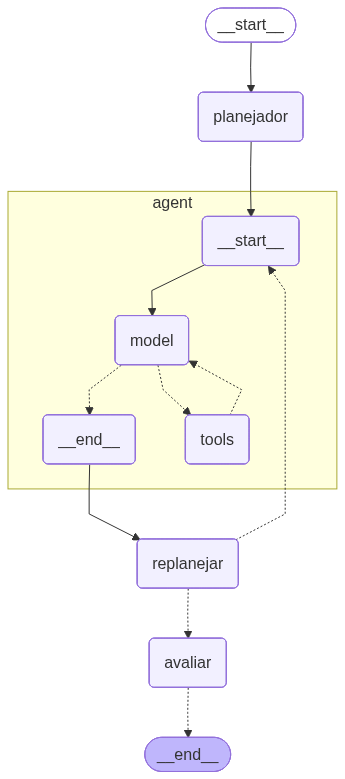

In [18]:
display(Image(app.get_graph(xray=True).draw_mermaid_png()))

## 10. Execução de Exemplo

In [19]:
def construir_bloco_tickets(df_lote: pd.DataFrame) -> str:
    linhas = []
    for _, ticket in df_lote.iterrows():
        linhas.append(
            f"Ticket: {ticket.get('Id', ticket.get('id', ''))}\n"
            f"Assunto: {ticket.get('assunto', ticket.get('Assunto', ''))}\n"
            f"Descricao: {ticket.get('descricao', ticket.get('Descrição', ''))}\n"
            f"Tipo: {ticket.get('tipo', ticket.get('Tipo', ''))}\n"
            f"Resposta de referência: {ticket.get('resposta', ticket.get('Resposta', ''))}"
        )
    return "\n\n---\n\n".join(linhas)


def gerar_prompt_analise_itil(df: pd.DataFrame, quantidade: int = 30, inicio: int = 0) -> str:
    df_slice = df.iloc[inicio:inicio + quantidade]
    if df_slice.empty:
        raise ValueError(f"Nenhum ticket disponível no intervalo {inicio}:{inicio + quantidade}.")

    prompt_texto = "Por favor, analise os seguintes tickets aplicando as diretrizes da ITIL 4 estabelecidas:\n"
    prompt_texto += "Para cada ticket, retorne qual Prática ITIL evitaria o incidente e resolveria o problema previamente.\n"
    prompt_texto += "---\n\n"
    prompt_texto += construir_bloco_tickets(df_slice)
    prompt_texto += "\n\nE retorne qual Prática ITIL que evitaria esse incidente e poderia resolver o problema previamente."
    return prompt_texto


async def executar_em_lote(prompt_lote: str) -> str:
    config = {"recursion_limit": 50}
    inputs = {"input": prompt_lote}
    resposta_final = ""
    async for event in app.astream(inputs, config=config):
        for k, v in event.items():
            if k != "__end__":
                print(f"\n--- Nó: {k} ---")
                print(v)
                if k == "replanejar" and isinstance(v, dict):
                    resposta_final = v.get("response", resposta_final)
                if k == "avaliar" and isinstance(v, dict) and not v.get("evaluation_feedback"):
                    print("🎉 Resposta final aprovada e entregue.")
    return resposta_final


def salvar_resposta_markdown(caminho_md: str, lote_numero: int, resposta: str) -> None:
    with open(caminho_md, "a", encoding="utf-8") as arquivo_md:
        arquivo_md.write(f"## Lote {lote_numero}\n\n")
        arquivo_md.write((resposta or "").strip())
        arquivo_md.write("\n\n---\n\n")


async def processar_lotes(
    df: pd.DataFrame,
    num_lote: int = 5,
    tamanho_lote: int = 30,
    arquivo_md: str = "resposta_itil_agent_plan_exec_avaliar.md"
 ) -> None:
    total_lotes = num_lote
    limite_total = min(len(df), total_lotes * tamanho_lote)
    if limite_total == 0:
        raise ValueError("Nenhum ticket disponível para processamento.")

    with open(arquivo_md, "w", encoding="utf-8") as arquivo_md_saida:
        arquivo_md_saida.write("# Respostas ITIL por Lote - Planejar, Executar e Avaliar\n\n")

    for lote_numero in range(total_lotes):
        inicio = lote_numero * tamanho_lote
        fim = inicio + tamanho_lote
        if inicio >= limite_total:
            print(f"Lote {lote_numero + 1}: nenhum ticket restante.")
            break

        prompt_lote = gerar_prompt_analise_itil(df, quantidade=tamanho_lote, inicio=inicio)
        print(f"Processando lote {lote_numero + 1}/{total_lotes} com tickets {inicio + 1} a {min(fim, limite_total)}...")
        try:
            resposta_lote = await executar_em_lote(prompt_lote)
        except Exception as ex:
            resposta_lote = f"Falha ao processar o lote {lote_numero + 1}: {ex}"
            print(resposta_lote)
        salvar_resposta_markdown(arquivo_md, lote_numero + 1, resposta_lote)


print("✅ Funções de lote para planejar-executar-avaliar prontas.")

✅ Funções de lote para planejar-executar-avaliar prontas.


In [20]:
if 'df_tickets' not in globals():
    if os.path.exists("df_tickets_pt.csv"):
        df_tickets = pd.read_csv("df_tickets_pt.csv")
    elif os.path.exists("df_tickets.csv"):
        df_tickets = pd.read_csv("df_tickets.csv")
    else:
        raise FileNotFoundError("Não encontrei df_tickets_pt.csv nem df_tickets.csv no diretório do notebook.")

await processar_lotes(
    df_tickets,
    num_lote=5,
    tamanho_lote=30,
    arquivo_md="resposta_itil_agent_plan_exec_avaliar.md"
 )

Processando lote 1/5 com tickets 1 a 30...

--- Nó: planejador ---
{'plan': ['Para o Ticket 3 (Erro na Autocompletação de Código do IntelliJ IDEA), a Prática ITIL que evitaria o incidente e resolveria o problema previamente é a Gestão de Problemas (Problem Management), investigando a causa raiz do travamento, e a Validação e Teste de Serviço (Service Validation and Testing), garantindo que o software seja testado adequadamente antes do lançamento.', 'Para o Ticket 25 (Problemas intermitentes de exibição após atualização de firmware), a Prática ITIL que evitaria o incidente e resolveria o problema previamente é a Habilitação de Mudanças (Change Enablement) e a Validação e Teste de Serviço (Service Validation and Testing), garantindo que as atualizações de firmware sejam testadas rigorosamente antes da implantação.', 'Para o Ticket 42 (Pedido de Assistência para Administração de Servidores), a Prática ITIL que evitaria o incidente e resolveria o problema previamente é a Melhoria Contínua